In [188]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import time


from utils_ML import score_dataset
from utils_preproces import ols_fit, y_distribution_plot, corr_heatmap_plot, make_mi_scores, preprocess_data

from sklearn.ensemble import RandomForestRegressor, VotingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor, plot_importance
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold


from sklearn.metrics import mean_absolute_error

In [189]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [190]:
# Fix random state
random_state = 42

In [191]:
harps = pd.read_csv('harps_sample.csv')
apogee = pd.read_csv('apogee_sample.csv')
galah = pd.read_csv('galah_sample.csv')

print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')

harps contains 798 stars
apogee contains 108526 stars
galah contains 116050 stars


# Here we focus on getting Fe from no abundance

In [192]:
columns_for_Fe = ['radial_velocity', 'V_lsr',  'U_lsr',  'W_lsr', 'P_gal', 
                'fe_h', ]

apogee = apogee[columns_for_Fe]
harps = harps[columns_for_Fe]
galah = galah[columns_for_Fe]

In [ ]:
def fit_trasform(X):
    X['VW_lsr'] = np.sqrt(X['V_lsr']**2 + X['W_lsr']**2)
    X['UW_lsr'] = np.sqrt(X['U_lsr']**2 + X['W_lsr']**2)
    X['UV_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2)
    epsilon = 1e-6
    #log features
    #X['Log_RV'] = np.log(X['RV'] + np.abs(X['RV'].min()))
    #X['Log_U_lsr'] = np.log(X['U_lsr'] + np.abs(X['U_lsr'].min()) + epsilon)
    #X['Log_V_lsr'] = np.log(X['V_lsr'] + np.abs(X['V_lsr'].min()) + epsilon)
    #X['Log_W_lsr'] = np.log(X['W_lsr'] + np.abs(X['W_lsr'].min()) + epsilon)
    #X['Log_UW_lsr'] = np.log(X['UW_lsr'])
    #X['Log_UVW_lsr'] = np.log(X['UVW_lsr'])

    return X

#apogee = fit_trasform(apogee)
#harps = fit_trasform(harps)

### Identifying and exluding null values

In [195]:
apogee.isnull().sum()

radial_velocity      0
V_lsr                0
U_lsr                0
W_lsr                0
P_gal              196
fe_h                 0
dtype: int64

In [196]:
apogee.dropna(inplace = True)

In [197]:
harps.isnull().sum()

radial_velocity    0
V_lsr              0
U_lsr              0
W_lsr              0
P_gal              0
fe_h               0
dtype: int64

### Spliting data into Trianing and Testing sets

In [198]:
apogee_train_full, apogee_test = train_test_split(apogee, test_size=0.1, random_state=random_state)
y_apogee = apogee_train_full['fe_h']
X_apogee = apogee_train_full.drop(columns = ['fe_h'])

y_harps = harps['fe_h']
X_harps = harps.drop(columns = ['fe_h'])

In [199]:
rfr = RandomForestRegressor(random_state=random_state, n_jobs=-1)
xgbr = XGBRegressor(random_state=random_state, n_jobs=-1)
lr = LinearRegression()  # no internal parallel
svr = SVR()  # no internal parallel
lgbr = LGBMRegressor(random_state=random_state, verbosity=-1, n_jobs=-1)
catr = CatBoostRegressor(random_state=random_state, verbose=False, thread_count=-1)
extr = ExtraTreesRegressor(random_state=random_state, n_jobs=-1)


voting_r = VotingRegressor(estimators=[
    ('xgbr', xgbr),
    #('rfr', rfr),
    ('extr', extr),
    ('lgbr', lgbr),
    ('catr', catr)
])

model_names = {
    'xgbr': xgbr,
    #'rfr': rfr,
    'extr': extr,  
    #'svr': svr,
    #'lr': lr,
    'lgbr': lgbr,
    'catr': catr,
    #'voting_r': voting_r
}


In [200]:
def model_test_CV_models(X, y, models, k=5, random_state=random_state):
    """
    Perform k-fold cross-validation for multiple models and return mean MAE scores and elapsed time.

    Parameters:
        X (DataFrame): Feature matrix.
        y (Series): Target vector.
        models (dict): Dictionary of model_name: model_instance.
        k (int): Number of folds.
        random_state (int): Seed for reproducibility.

    Returns:
        dict: {model_name: {'mean_mae': ..., 'std_mae': ..., 'time_sec': ...}}
    """
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    results = {}

    for name, model in models.items():
        print(f"Scoring model: {name}")
        start_time = time.time()
        mae_scores = []

        for train_index, test_index in kf.split(X, y):
            X_train, X_test = X.iloc[train_index], X.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            mae = mean_absolute_error(y_test, y_pred)
            mae_scores.append(mae)

        elapsed_time = time.time() - start_time
        results[name] = {
            'mean_mae': np.mean(mae_scores),
            'std_mae': np.std(mae_scores),
            'time_sec': elapsed_time
        }

        print(f"{name} done in {elapsed_time:.2f}s → MAE: {results[name]['mean_mae']:.3f} ± {results[name]['std_mae']:.3f}\n")

    return results


In [202]:
baseline_results = model_test_CV_models(X_apogee, y_apogee, model_names, k=5)

for name, score in baseline_results.items():
    print(f"{name:8s} | MAE: {score['mean_mae']:.3f} ± {score['std_mae']:.3f}")


Scoring model: xgbr


xgbr done in 1.30s → MAE: 0.192 ± 0.001

Scoring model: extr
extr done in 13.43s → MAE: 0.196 ± 0.001

Scoring model: lgbr


KeyboardInterrupt: 

In [ ]:
def evaluate_on_test_sets(X_train, y_train, X_test1, y_test1, X_test2, y_test2, models):
    """
    Trains models on full training set and evaluates on two test sets.

    Parameters:
        X_train, y_train: Training data.
        X_test1, y_test1: First test set (e.g., Apogee test).
        X_test2, y_test2: Second test set (e.g., HARPS).
        models: Dictionary of model_name: model_instance.

    Returns:
        dict: model_name → test MAEs on both test sets
    """
    results = {}

    for name, model in models.items():
        print(f"Training and evaluating {name}")
        model.fit(X_train, y_train)

        y_pred1 = model.predict(X_test1)
        y_pred2 = model.predict(X_test2)

        mae_fixed1 = mean_absolute_error(y_test1, np.full(len(y_test1), np.mean(y_test1)))
        mae_fixed2 = mean_absolute_error(y_test2, np.full(len(y_test2), np.mean(y_test2)))

        mae1 = mean_absolute_error(y_test1, y_pred1)
        mae2 = mean_absolute_error(y_test2, y_pred2)

        results[name] = {
            'apogee_test_mae': mae1,
            'harps_test_mae': mae2
        }

        print(f"{name} | Apogee MAE: {mae1:.2f} (for mean: {mae_fixed1:.2f}) | HARPS MAE: {mae2:.2f} (for mean: {mae_fixed2:.2f})\n")

    return results


In [ ]:
X_harps

,radial_velocity,V_lsr,U_lsr,W_lsr,P_gal
0,4.559510,-22.977043,65.848610,-21.985845,94.1
1,40.148790,-35.863697,-46.832549,6.384363,96.7
2,23.582409,-14.033852,11.082570,4.621676,99.0
3,-20.974250,18.000079,9.529661,3.436266,99.0
4,8.300105,8.249129,40.959611,16.192835,98.3
...,...,...,...,...,...
793,27.459513,-20.992697,-38.323480,3.083373,98.5
794,-6.991496,-8.174493,-6.016581,9.342134,99.0
795,5.715332,-17.633346,3.735148,20.690320,98.1
796,-8.150976,1.778079,18.796714,2.865190,99.1


In [ ]:
X_test_apogee = apogee_test.drop(columns='fe_h')
y_test_apogee = apogee_test['fe_h']


test_results = evaluate_on_test_sets(
    X_apogee, y_apogee,
    X_test_apogee, y_test_apogee,
    X_harps, y_harps,
    model_names
)


Training and evaluating xgbr
xgbr | Apogee MAE: 0.19 (for mean: 0.22) | HARPS MAE: 0.18 (for mean: 0.20)

Training and evaluating extr
extr | Apogee MAE: 0.20 (for mean: 0.22) | HARPS MAE: 0.19 (for mean: 0.20)

Training and evaluating lgbr
lgbr | Apogee MAE: 0.19 (for mean: 0.22) | HARPS MAE: 0.18 (for mean: 0.20)

Training and evaluating catr
catr | Apogee MAE: 0.19 (for mean: 0.22) | HARPS MAE: 0.18 (for mean: 0.20)



In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_residuals_vs_true(y_true, y_pred, model_name='Model', sample_name='Test Set'):
    """
    Plot residuals (y_true - y_pred) vs y_true, and residuals from predicting the mean.

    Parameters:
        y_true: Ground truth target values.
        y_pred: Model predictions.
        model_name: Name of the model for labeling.
        sample_name: Name of the dataset (e.g., 'Apogee' or 'HARPS').
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_mean = np.full_like(y_true, y_true.mean())

    residuals_model = y_true - y_pred
    residuals_mean = y_true - y_mean

    plt.figure(figsize=(10, 6))
    plt.scatter(y_true, residuals_model, alpha=0.6, label=f'{model_name}', s=20)
    plt.scatter(y_true, residuals_mean, alpha=0.4, label='Mean predictor', s=20, marker='x')

    plt.axhline(0, color='gray', linestyle='--')
    plt.xlabel('True Value (y)')
    plt.ylabel('Residual (y_true - y_pred)')
    plt.title(f'Residuals vs True Values ({sample_name})')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


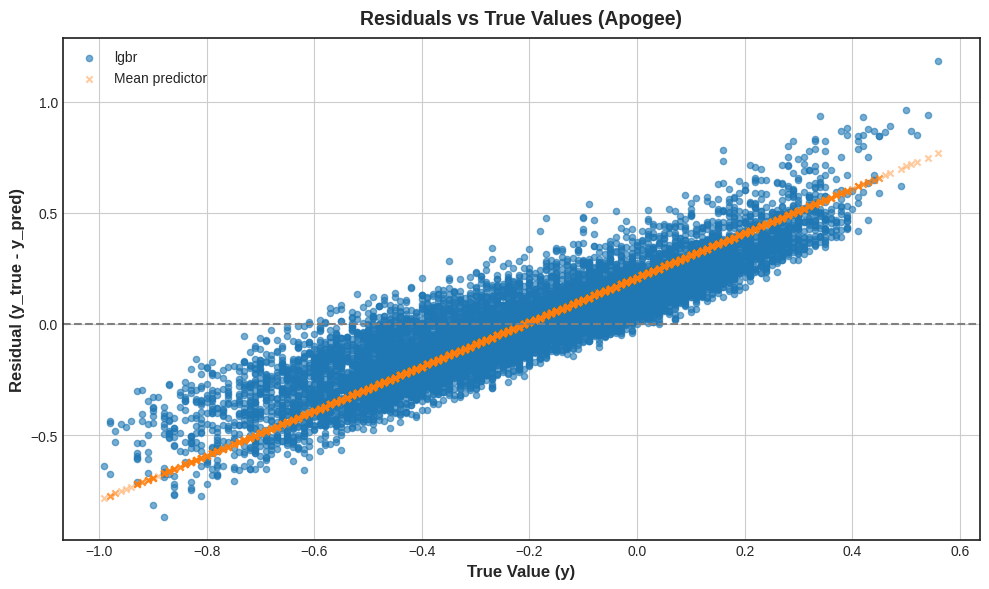

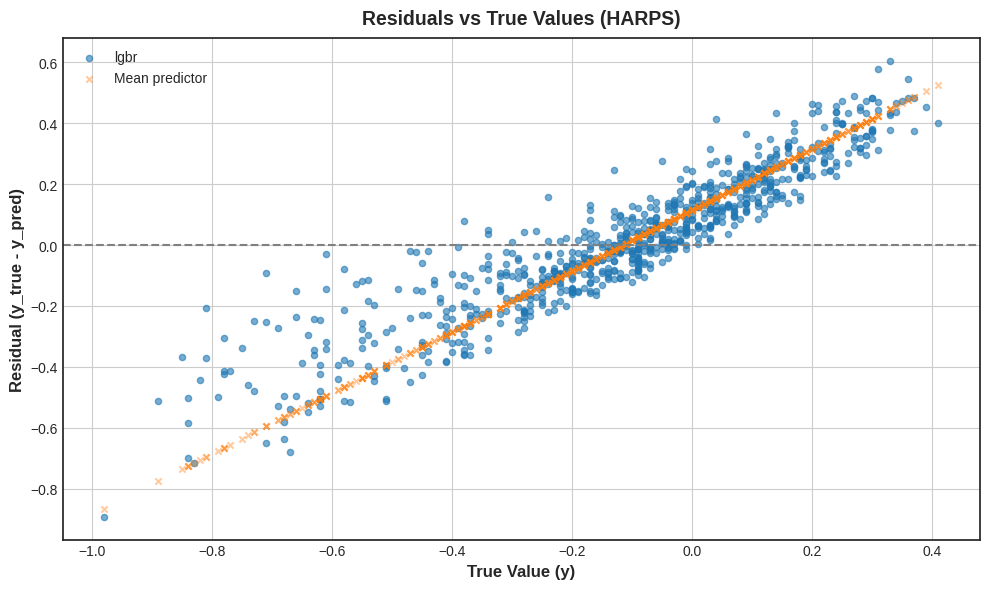

In [ ]:
# Example for one model and one test set
best_model_name = 'lgbr'
model = model_names[best_model_name]
model.fit(X_apogee, y_apogee)

y_pred_apogee = model.predict(X_test_apogee)
plot_residuals_vs_true(y_test_apogee, y_pred_apogee, model_name=best_model_name, sample_name='Apogee')

y_pred_harps = model.predict(X_harps)
plot_residuals_vs_true(y_harps, y_pred_harps, model_name=best_model_name, sample_name='HARPS')
